In [ ]:
"""
Figure 3 - Ice displacement at LEV6, KAN_U, F003 and F004, and annual cumulative PDH at KAN_U. 
Author: Hannah Picton 
Date: 26th March 2026
Description: This notebook plots ice displacement at (a) LEV6 and (b) KAN_U between 2009-2012 and 2021-2023, and at (c) F004 and (d) F003 between 1996 and 2021-2023. (e) Annual cumulative PDH at KAN_U between 2009 and 2023. 
Ice displacement data for 2009-2012 can be found at Tedstone & Nienow (2018; https://doi.org/10.5285/1f69fba3-4c62-47ad-8119-08cfeec05e46) and for 2021-2023 at Tedstone et al. (2026; https://doi.org/10.5281/zenodo.18611668). 
Ice displacement data for F003 and F004 in 1996 can be found at https://ubwp.buffalo.edu/glyremotesensinglab/2024/05/22/mass-balance-and-velocity-data-for-greenlands-ice-sheets-at-high-elevations-data/.
PDH data is derived from hourly data from the automatic weather station (AWS) at KAN_U, which is made available through PROMICE (http://www.promice.dk).  
"""

# Import libraries 
import os
import pandas as pd
import matplotlib.pyplot as plt
import glob
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

# -- PROVIDE PATH TO ICE DISPLACEMENT DATA (LEV6 & KANU, F004 & F003) --
displacement_data_path = '.../data/' # UPDATE FILEPATH
folders_6_kanu = ['seasonal_annual_2009_2013', 'seasonal_annual_2020_2024']
folders_4_3 = ['seasonal_annual_2020_2024']

# -- PROVIDE PATH TO AWS DATA FROM KAN_U --
kan_u_hourly = pd.read_csv('.../data/KAN_U_hour.csv') # UPDATE FILEPATH

# Prepare AWS data from KAN_U
kan_u_hourly['time'] = pd.to_datetime(kan_u_hourly['time'])
kan_u_hourly.set_index('time', inplace=True)
kan_u_filtered = kan_u_hourly.loc[(kan_u_hourly.index >= '2009-05-01') & (kan_u_hourly.index < '2024-05-01')].copy()
kan_u_filtered['PDH'] = kan_u_filtered['t_u'].clip(lower=0)
kan_u_filtered['offset_year'] = (kan_u_filtered.index - pd.DateOffset(months=4)).year
pdh_kan_u_annual = kan_u_filtered.groupby('offset_year')['PDH'].sum()
mean_pdh_kan_u = pdh_kan_u_annual.mean()

# Define plot colours
winter_color = '#126782'
early_summer_color = '#58b4d1'
late_summer_color = '#8ecae6'
summer_color = '#219ebc'
annual_color = '#14213d'

# Define plotting parameters for LEV6/KANU and F004/F003
years_6_kanu = [2009, 2010, 2011, 2012, 2021, 2022, 2023]
mapping_6_kanu = {2009: 0, 2010: 1, 2011: 2, 2012: 3, 2021: 4.5, 2022: 5.5, 2023: 6.5}
years_4_3 = [1996, 2021, 2022, 2023]
mapping_4_3 = {1996: 0, 2021: 1.5, 2022: 2.5, 2023: 3.5}

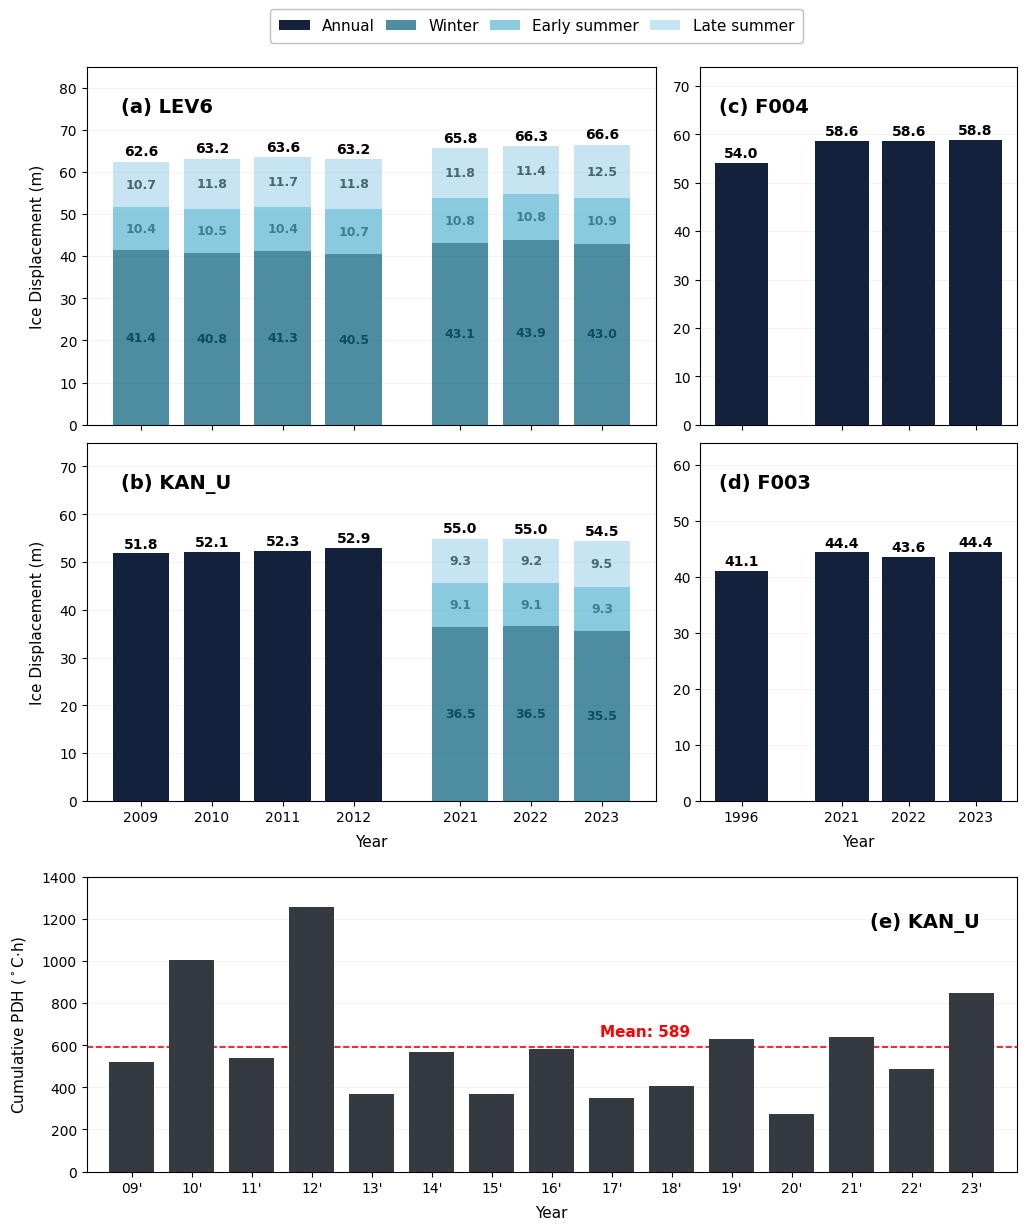

In [ ]:
# Plot ice displacement at (a) LEV6 and (b) KAN_U between 2009-2012 and 2021-2023, and at (c) F004 and (d) F003 between 1996 and 2021-2023. (e) Annual cumulative PDH at KAN_U between 2009 and 2023.
fig = plt.figure(figsize=(12, 13))
gs_master = fig.add_gridspec(2, 1, height_ratios=[1.5, 0.65], hspace=0.1) # 1. Create a master grid: 2 rows (Top half for a-d, Bottom half for e)
gs_upper = gs_master[0, 0].subgridspec(2, 2, width_ratios=[1.8, 1], hspace=0.05, wspace=0.1) # 2. Create the upper nested grid (for subplots a-d)

def plot_stacked_site(ax, site, folders, years, mapping, label):
    store = []
    for folder in folders:
        fglob = os.path.join(displacement_data_path, folder, f'{site}_seasonal_annual_*.csv')
        for fs in glob.glob(fglob):
            store.append(pd.read_csv(fs))
    if not store:
        return
    all_data = pd.concat(store, axis=0)
    # Pivot by seasonal component
    es = all_data[all_data.period == 'ES'].pivot(index='year', values='disp_m', columns='site')
    ls = all_data[all_data.period == 'LS'].pivot(index='year', values='disp_m', columns='site')
    winter = all_data[all_data.period == 'Winter'].pivot(index='year', values='disp_m', columns='site')
    summer = all_data[all_data.period == 'Summer'].pivot(index='year', values='disp_m', columns='site')
    annual = all_data[all_data.period == 'Annual'].pivot(index='year', values='disp_m', columns='site')
    for year in years:
        if year not in mapping:
            continue
        x_pos = mapping[year]
        # ---- FORCE annual-only for KANU 2009–2012 ----
        if site == 'kanu' and year in [2009, 2010, 2011, 2012] and year in annual.index:
            a_val = annual.loc[year, site]
            ax.bar(x_pos, a_val, color=annual_color, zorder=3)
            ax.annotate(f'{a_val:.1f}', xy=(x_pos, a_val), xytext=(0, 4), textcoords='offset points', ha='center', weight='bold', zorder=4)
            continue
        # Case 1: Full breakdown (ES + LS + Winter)
        if year in es.index and year in ls.index and year in winter.index:
            w_val = winter.loc[year, site]
            es_val = es.loc[year, site]
            ls_val = ls.loc[year, site]
            ax.bar(x_pos, w_val, color=winter_color, alpha=0.75, zorder=5)
            ax.bar(x_pos, es_val, bottom=w_val, color=early_summer_color, alpha=0.7, zorder=5)
            ax.bar(x_pos, ls_val, bottom=w_val + es_val, color=late_summer_color, alpha=0.5, zorder=5)
            for val, base in [(w_val, 0), (es_val, w_val), (ls_val, w_val + es_val)]:
                if val > 0:
                    ax.annotate(f'{val:.1f}', xy=(x_pos, base + val/2), ha='center', va='center', weight='bold', fontsize=9, zorder=4)
            if year in annual.index and site in annual.columns and pd.notna(annual.loc[year, site]):
                total_val = annual.loc[year, site]
            else:
                total_val = w_val + es_val + ls_val
            ax.annotate(f'{total_val:.1f}', xy=(x_pos, total_val), xytext=(0, 4), textcoords='offset points', ha='center', weight='bold', zorder=4)
        # Case 2: Winter + Summer only
        elif year in winter.index and year in summer.index:
            w_val = winter.loc[year, site]
            s_val = summer.loc[year, site]
            ax.bar(x_pos, w_val, color=winter_color, alpha=0.75, zorder=5)
            ax.bar(x_pos, s_val, bottom=w_val, color=summer_color, alpha=0.7, zorder=5)
            for val, base in [(w_val, 0), (s_val, w_val)]:
                if val > 0:
                    ax.annotate(f'{val:.1f}', xy=(x_pos, base + val/2), ha='center', va='center', weight='bold', fontsize=9, zorder=4)
            if year in annual.index and site in annual.columns and pd.notna(annual.loc[year, site]):
                total_val = annual.loc[year, site]
            else:
                total_val = w_val + s_val
            ax.annotate(f'{total_val:.1f}', xy=(x_pos, total_val), xytext=(0, 4), textcoords='offset points', ha='center', weight='bold', zorder=4)
        # Case 3: Annual only
        elif year in annual.index:
            a_val = annual.loc[year, site]
            ax.bar(x_pos, a_val, color=annual_color, zorder=3)
            ax.annotate(f'{a_val:.1f}', xy=(x_pos, a_val), xytext=(0, 4), textcoords='offset points', ha='center', weight='bold', zorder=4)
    x_pos_label = 0.04 if label in ['(a)', '(b)'] else 0.06
    ax.text(x_pos_label, 0.915, label, transform=ax.transAxes, fontsize=14, fontweight='bold', va='top')
    ax.grid(axis='y', alpha=0.15, zorder=0)

# --- Subplot (a) LEV6 ---
ax1 = fig.add_subplot(gs_upper[0, 0])
plot_stacked_site(ax1, 'lev6', folders_6_kanu, years_6_kanu, mapping_6_kanu, '(a) LEV6')
ax1.set_xticks(list(mapping_6_kanu.values()))
ax1.set_xticklabels([])
ax1.set_ylim(0, 85)
ax1.set_ylabel('Ice Displacement (m)', labelpad=10, fontsize=11)

# --- Subplot (b) KANU ---
ax2 = fig.add_subplot(gs_upper[1, 0])
plot_stacked_site(ax2, 'kanu', folders_6_kanu, years_6_kanu, mapping_6_kanu, '(b) KAN_U')
ax2.set_xticks(list(mapping_6_kanu.values()))
ax2.set_xticklabels(years_6_kanu)
ax2.set_ylim(0, 75)
ax2.set_xlabel('Year', labelpad=7, fontsize=11)
ax2.set_ylabel('Ice Displacement (m)', labelpad=10, fontsize=11)

# --- Subplot (c) F004 ---
ax3 = fig.add_subplot(gs_upper[0, 1])
plot_stacked_site(ax3, 'f004', folders_4_3, years_4_3, mapping_4_3, '(c) F004')
ax3.set_xticks(list(mapping_4_3.values()))
ax3.set_xticklabels([])
ax3.set_ylim(0, 74)

# --- Subplot (d) F003 ---
ax4 = fig.add_subplot(gs_upper[1, 1])
plot_stacked_site(ax4, 'f003', folders_4_3, years_4_3, mapping_4_3, '(d) F003')
ax4.set_xticks(list(mapping_4_3.values()))
ax4.set_xticklabels(years_4_3)
ax4.set_ylim(0, 64)
ax4.set_xlabel('Year', labelpad=7, fontsize=11)

# --- Subplot (e) KAN_U PDH ---
ax5 = fig.add_subplot(gs[2, :])
pdh_plot = pdh_kan_u_annual.loc[2009:2023]
ax5.bar(pdh_plot.index, pdh_plot.values, color='#343a40', alpha=1, width=0.75, zorder=5)
ax5.set_ylabel(r'Cumulative PDH ($^\circ$C$\cdot$h)', fontsize=11, labelpad=10)
ax5.set_xlabel('Year', labelpad=7, fontsize=11)
ax5.set_xticks(pdh_plot.index)
ax5.set_xticklabels([f"{str(y)[-2:]}'" for y in pdh_plot.index])
ax5.set_ylim(0, 1400)
ax5.set_xlim(2008.25, 2023.75)
ax5.grid(axis='y', linestyle='-', alpha=0.15, zorder=0)
ax5.axhline(mean_pdh_kan_u, color='red', linestyle='--', linewidth=1.2, zorder=1) # Add mean PDH 
ax5.text(pdh_plot.index[-1] - 4.7, mean_pdh_kan_u + 40, f'Mean: {mean_pdh_kan_u:.0f}', va='bottom', ha='right', color='red', fontweight='bold', fontsize=11) 
ax5.text(0.96, 0.88, '(e) KAN_U', transform=ax5.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

# Legend formatting for (a)-(d)
legend_elements = [Patch(facecolor=annual_color, label='Annual'),
    Patch(facecolor=winter_color, alpha=0.75, label='Winter'),
    Patch(facecolor=early_summer_color, alpha=0.7, label='Early summer'),
    Patch(facecolor=late_summer_color, alpha=0.5, label='Late summer'),]
fig.legend(handles=legend_elements, loc='upper center', ncol=4, frameon=True, bbox_to_anchor=(0.5, 1.01), columnspacing=0.7, fontsize=11, facecolor='white', borderpad=0.6, framealpha=0.5, edgecolor='grey')

plt.subplots_adjust(top=0.96) 
plt.show()